In [8]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


# 1. Random Forest

## 1.1 Objetivo

Implementar e avaliar o algoritmo Random Forest para classificação de clientes quanto à ocorrência de cancelamento dos serviços de telecomunicações (Churn).

Serão investigadas duas configurações de hiperparâmetros, utilizando validação cruzada estratificada com cinco partições previamente preparadas.

O desempenho será avaliado por meio das métricas de acurácia, precisão, revocação, F1-score e matriz de confusão.


In [9]:

from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")

print("Biblioteca da Random Florest importada com sucesso.")


Biblioteca da Random Florest importada com sucesso.


In [10]:
# Identificando diretório do projeto

current_dir = Path.cwd().resolve()

if current_dir.name.lower() == "notebooks":
    project_dir = current_dir.parent
else:
    project_dir = current_dir

# Localização do Dataset
fold_dir = project_dir / "data" / "processed" / "folds"

# Diretorio dos resultados
results_dir = project_dir / "reports" / "modelos"
results_dir.mkdir(parents=True, exist_ok=True)

print("Project:", project_dir)
print("Folds:", fold_dir)
print("Results:", results_dir)


Project: /home/joaovictor/telco-churn-grupo1
Folds: /home/joaovictor/telco-churn-grupo1/data/processed/folds
Results: /home/joaovictor/telco-churn-grupo1/reports/modelos


In [11]:
# Definindo configurações das duas Random Forest que vão ser criadas

rf_configurations = {

    "RF_A_Baseline": { # A primeira não tem uma profundidade definida
        "n_estimators": 300,
        "max_depth": None,
        "min_samples_split": 2,
        "min_samples_leaf": 1,
        "max_features": "sqrt",
        "class_weight": None
    },

    "RF_B_Regularized": { # A segunda tem uma profundidade definida de 12 níveis
        "n_estimators": 300,
        "max_depth": 12,
        "min_samples_split": 2,
        "min_samples_leaf": 2,
        "max_features": "sqrt",
        "class_weight": None
    }

}

display(pd.DataFrame(rf_configurations).T)


,n_estimators,max_depth,min_samples_split,min_samples_leaf,max_features,class_weight
RF_A_Baseline,300,None,2,1,sqrt,None
RF_B_Regularized,300,12,2,2,sqrt,None


In [12]:
# Metricas coletadas para cada fold
rf_results = []

# Matrizes de confusão e predições
rf_confusion_matrices = {}
rf_oof_results = {}

# Recursos de importancia dos folds
rf_feature_importances = {}

metric_columns = [
    "Acurácia (accuracy)",
    "Precisão (precision)",
    "Revocação (recall)",
    "F1-score"
]

# Run each configuration
for configuration_name, parameters in rf_configurations.items():

    print("\n" + "=" * 65)
    print(f"RODANDO: {configuration_name}")
    print("=" * 65)

    total_confusion_matrix = np.zeros((2, 2), dtype=int)

    all_y_true = []
    all_y_pred = []

    fold_importances = []

    # Execute five-fold cross-validation
    for fold_number in range(1, 6):

        fold_path = fold_dir / f"fold_{fold_number}.npz"

        # Load the prepared fold
        with np.load(fold_path, allow_pickle=False) as fold:

            X_train = fold["X_train"]
            X_valid = fold["X_valid"]

            y_train = fold["y_train"]
            y_valid = fold["y_valid"]

            feature_names = fold["feature_names"].astype(str)

        # Initialize classifier
        model = RandomForestClassifier(
            **parameters,
            random_state=42,
            n_jobs=-1
        )

        # Train
        model.fit(X_train, y_train)

        # Predict
        y_pred = model.predict(X_valid)

        # Calculate metrics
        accuracy = accuracy_score(y_valid, y_pred)

        precision = precision_score(
            y_valid, y_pred,
            pos_label=1,
            zero_division=0
        )

        recall = recall_score(
            y_valid, y_pred,
            pos_label=1,
            zero_division=0
        )

        f1 = f1_score(
            y_valid, y_pred,
            pos_label=1,
            zero_division=0
        )

        # Calculate confusion matrix
        cm = confusion_matrix(
            y_valid,
            y_pred,
            labels=[0, 1]
        )

        # Accumulate results
        total_confusion_matrix += cm

        all_y_true.extend(y_valid.tolist())
        all_y_pred.extend(y_pred.tolist())

        fold_importances.append(
            pd.Series(
                model.feature_importances_,
                index=feature_names
            )
        )

        # Save individual fold results
        rf_results.append({
            "Configuração": configuration_name,
            "fold": fold_number,
            "Acurácia (accuracy)": accuracy,
            "Precisão (precision)": precision,
            "Revocação (recall)": recall,
            "F1-score": f1
        })

        print(
            f"Fold {fold_number}: "
            f"Acurácia (accuracy)={accuracy:.4f} | "
            f"Precisão (precision)={precision:.4f} | "
            f"Revocação (recall)={recall:.4f} | "
            f"F1-score={f1:.4f}"
        )

    # Save aggregated confusion matrix
    rf_confusion_matrices[configuration_name] = (
        total_confusion_matrix
    )

    # Save average feature importance
    rf_feature_importances[configuration_name] = (
        pd.concat(fold_importances, axis=1)
        .mean(axis=1)
        .sort_values(ascending=False)
    )

    # Calculate overall out-of-fold metrics
    oof_accuracy = accuracy_score(all_y_true, all_y_pred)

    oof_precision = precision_score(
        all_y_true,
        all_y_pred,
        pos_label=1,
        zero_division=0
    )

    oof_recall = recall_score(
        all_y_true,
        all_y_pred,
        pos_label=1,
        zero_division=0
    )

    oof_f1 = f1_score(
        all_y_true,
        all_y_pred,
        pos_label=1,
        zero_division=0
    )

    rf_oof_results[configuration_name] = {
        "accuracy": oof_accuracy,
        "precision": oof_precision,
        "recall": oof_recall,
        "f1_score": oof_f1
    }

print("\nTodos experimentos de Random Forest foram terminados!")



RODANDO: RF_A_Baseline
Fold 1: Acurácia (accuracy)=0.7892 | Precisão (precision)=0.6442 | Revocação (recall)=0.4599 | F1-score=0.5367
Fold 2: Acurácia (accuracy)=0.7999 | Precisão (precision)=0.6631 | Revocação (recall)=0.5000 | F1-score=0.5701
Fold 3: Acurácia (accuracy)=0.8048 | Precisão (precision)=0.6701 | Revocação (recall)=0.5214 | F1-score=0.5865
Fold 4: Acurácia (accuracy)=0.7884 | Precisão (precision)=0.6218 | Revocação (recall)=0.5187 | F1-score=0.5656
Fold 5: Acurácia (accuracy)=0.7997 | Precisão (precision)=0.6454 | Revocação (recall)=0.5416 | F1-score=0.5889

RODANDO: RF_B_Regularized
Fold 1: Acurácia (accuracy)=0.8041 | Precisão (precision)=0.6678 | Revocação (recall)=0.5214 | F1-score=0.5856
Fold 2: Acurácia (accuracy)=0.8084 | Precisão (precision)=0.6831 | Revocação (recall)=0.5187 | F1-score=0.5897
Fold 3: Acurácia (accuracy)=0.8204 | Precisão (precision)=0.6997 | Revocação (recall)=0.5668 | F1-score=0.6263
Fold 4: Acurácia (accuracy)=0.7990 | Precisão (precision)=0.6

In [13]:
# Tabelas dos resultados


rf_results_df = pd.DataFrame(rf_results)

display(
    rf_results_df.round(4)
)


# Média dos resultados por configuração
rf_summary = (
    rf_results_df
    .groupby("Configuração")[metric_columns]
    .agg(["mean", "std"])
)

# Simplify column names
rf_summary.columns = [
    f"{metric}_{stat}"
    for metric, stat in rf_summary.columns
]

display(rf_summary.round(4))


rf_oof_df = pd.DataFrame(rf_oof_results).T

display(rf_oof_df.round(4))


,Configuração,fold,Acurácia (accuracy),Precisão (precision),Revocação (recall),F1-score
0,RF_A_Baseline,1,0.7892,0.6442,0.4599,0.5367
1,RF_A_Baseline,2,0.7999,0.6631,0.5000,0.5701
2,RF_A_Baseline,3,0.8048,0.6701,0.5214,0.5865
3,RF_A_Baseline,4,0.7884,0.6218,0.5187,0.5656
4,RF_A_Baseline,5,0.7997,0.6454,0.5416,0.5889
5,RF_B_Regularized,1,0.8041,0.6678,0.5214,0.5856
6,RF_B_Regularized,2,0.8084,0.6831,0.5187,0.5897
7,RF_B_Regularized,3,0.8204,0.6997,0.5668,0.6263
8,RF_B_Regularized,4,0.7990,0.6426,0.5481,0.5916
9,RF_B_Regularized,5,0.8146,0.6783,0.5710,0.6201


,Acurácia (accuracy)_mean,Acurácia (accuracy)_std,Precisão (precision)_mean,Precisão (precision)_std,Revocação (recall)_mean,Revocação (recall)_std,F1-score_mean,F1-score_std
Configuração,,,,,,,,
RF_A_Baseline,0.7964,0.0073,0.6489,0.0188,0.5083,0.0308,0.5696,0.021
RF_B_Regularized,0.8093,0.0085,0.6743,0.0211,0.5452,0.0246,0.6027,0.019


,accuracy,precision,recall,f1_score
RF_A_Baseline,0.7964,0.6485,0.5083,0.5699
RF_B_Regularized,0.8093,0.6739,0.5452,0.6028


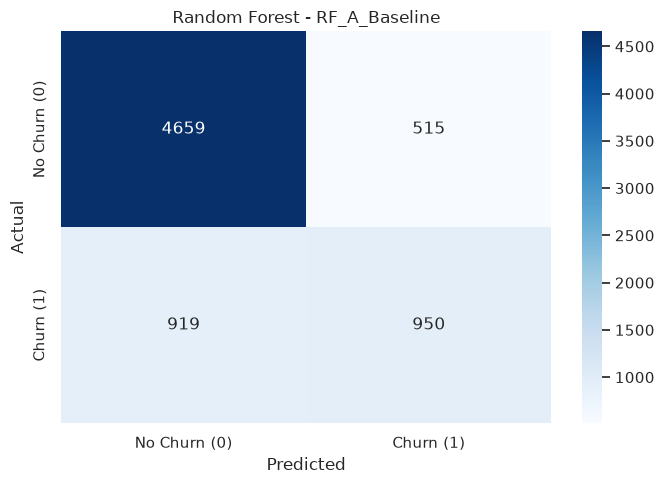

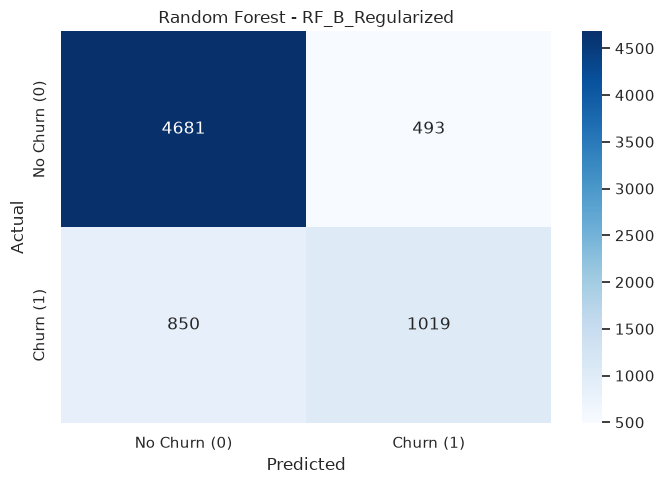

In [14]:
# Matriz de confusão

for configuration_name, cm in rf_confusion_matrices.items():

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Churn (0)", "Churn (1)"],
        yticklabels=["No Churn (0)", "Churn (1)"]
    )

    plt.title(
        f"Random Forest - {configuration_name}"
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.tight_layout()
    plt.show()


In [15]:
# Cria diretorio para matriz de confusão
confusion_dir = results_dir / "matrizes_confusao"
confusion_dir.mkdir(parents=True, exist_ok=True)

# Salva individualmente os resultados de fold
rf_results_df.to_csv(
    results_dir / "random_forest_resultados_por_fold.csv",
    index=False
)

# Salva o sumário
rf_summary.to_csv(
    results_dir / "random_forest_resumo.csv"
)

# Salva conjunto dos resultados de fold
rf_oof_df.to_csv(
    results_dir / "random_forest_resultados_oof.csv"
)

# Salva as matrizes de confusão
for configuration_name, cm in rf_confusion_matrices.items():

    cm_df = pd.DataFrame(
        cm,
        index=["Actual No Churn", "Actual Churn"],
        columns=["Predicted No Churn", "Predicted Churn"]
    )

    cm_df.to_csv(
        confusion_dir / f"{configuration_name}.csv"
    )


print("Resultados de Random Forest salvos!")


Resultados de Random Forest salvos!




# 2. XGBoost

## 2.1 Objetivo

Implementar e avaliar o algoritmo XGBoost para classificação de clientes quanto à ocorrência de cancelamento dos serviços de telecomunicações (Churn).

Serão investigadas duas configurações de hiperparâmetros, utilizando as mesmas cinco partições da validação cruzada estratificada aplicadas ao Random Forest.

O desempenho será avaliado por meio das métricas de acurácia, precisão, revocação, F1-score e matriz de confusão.


In [16]:
# Importa biblioteca de XGBoost e define configurações de parâmetros

from xgboost import XGBClassifier


xgb_configurations = {

    "XGB_A_Baseline": {
        "n_estimators": 200,
        "max_depth": 3,
        "learning_rate": 0.10,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 1
    },

    "XGB_B_Regularized": {
        "n_estimators": 400,
        "max_depth": 3,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "reg_lambda": 2
    }

}

display(pd.DataFrame(xgb_configurations).T)


,n_estimators,max_depth,learning_rate,subsample,colsample_bytree,reg_lambda
XGB_A_Baseline,200.0,3.0,0.10,0.8,0.8,1.0
XGB_B_Regularized,400.0,3.0,0.05,0.8,0.8,2.0


In [17]:

# Lista para guardar resultados
xgb_results = []

xgb_confusion_matrices = {}
xgb_oof_results = {}
xgb_feature_importances = {}

# Executa as duas configurações
for configuration_name, parameters in xgb_configurations.items():

    print("\n" + "=" * 65)
    print(f"RUNNING: {configuration_name}")
    print("=" * 65)

    total_confusion_matrix = np.zeros((2, 2), dtype=int)

    all_y_true = []
    all_y_pred = []

    fold_importances = []

    # Validação de cinco partições
    for fold_number in range(1, 6):

        fold_path = fold_dir / f"fold_{fold_number}.npz"

        # Carrega o fold
        with np.load(fold_path, allow_pickle=False) as fold:

            X_train = fold["X_train"]
            X_valid = fold["X_valid"]

            y_train = fold["y_train"]
            y_valid = fold["y_valid"]

            feature_names = fold["feature_names"].astype(str)

        # Cria um classificador
        model = XGBClassifier(
            **parameters,
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            random_state=42,
            n_jobs=-1
        )

        # Treina o modelo
        model.fit(X_train, y_train)

        # Prediz os resultados
        y_pred = model.predict(X_valid)

        # Calculo de métricas
        accuracy = accuracy_score(y_valid, y_pred)

        precision = precision_score(
            y_valid,
            y_pred,
            pos_label=1,
            zero_division=0
        )

        recall = recall_score(
            y_valid,
            y_pred,
            pos_label=1,
            zero_division=0
        )

        f1 = f1_score(
            y_valid,
            y_pred,
            pos_label=1,
            zero_division=0
        )

        # Matriz de confusão
        cm = confusion_matrix(
            y_valid,
            y_pred,
            labels=[0, 1]
        )

        total_confusion_matrix += cm

        all_y_true.extend(y_valid.tolist())
        all_y_pred.extend(y_pred.tolist())

        # Feature importance
        fold_importances.append(
            pd.Series(
                model.feature_importances_,
                index=feature_names
            )
        )

        # Armazena os resultados
        xgb_results.append({
            "configuration": configuration_name,
            "fold": fold_number,
            "accuracy": accuracy,
            "precision": precision,
            "recall": recall,
            "f1_score": f1
        })

        print(
            f"Fold {fold_number}: "
            f"Acurácia (accuracy)={accuracy:.4f} | "
            f"Precisão (precision)={precision:.4f} | "
            f"Revocação (recall)={recall:.4f} | "
            f"F1-score={f1:.4f}"
        )

    # Armazena matriz de confusão
    xgb_confusion_matrices[configuration_name] = (
        total_confusion_matrix
    )

    # Métricas de fold
    xgb_oof_results[configuration_name] = {
        "accuracy": accuracy_score(all_y_true, all_y_pred),

        "precision": precision_score(
            all_y_true, all_y_pred,
            pos_label=1,
            zero_division=0
        ),

        "recall": recall_score(
            all_y_true, all_y_pred,
            pos_label=1,
            zero_division=0
        ),

        "f1_score": f1_score(
            all_y_true, all_y_pred,
            pos_label=1,
            zero_division=0
        )
    }

print("\Todos experimentos de XGBoost realizados")



RUNNING: XGB_A_Baseline


<>:144: SyntaxWarning: invalid escape sequence '\T'
<>:144: SyntaxWarning: invalid escape sequence '\T'
/tmp/ipykernel_9869/2312059594.py:144: SyntaxWarning: invalid escape sequence '\T'
  print("\Todos experimentos de XGBoost realizados")


Fold 1: Acurácia (accuracy)=0.7984 | Precisão (precision)=0.6415 | Revocação (recall)=0.5455 | F1-score=0.5896
Fold 2: Acurácia (accuracy)=0.8070 | Precisão (precision)=0.6747 | Revocação (recall)=0.5267 | F1-score=0.5916
Fold 3: Acurácia (accuracy)=0.8204 | Precisão (precision)=0.6958 | Revocação (recall)=0.5749 | F1-score=0.6296
Fold 4: Acurácia (accuracy)=0.7990 | Precisão (precision)=0.6375 | Revocação (recall)=0.5642 | F1-score=0.5986
Fold 5: Acurácia (accuracy)=0.8146 | Precisão (precision)=0.6750 | Revocação (recall)=0.5791 | F1-score=0.6234

RUNNING: XGB_B_Regularized
Fold 1: Acurácia (accuracy)=0.8034 | Precisão (precision)=0.6550 | Revocação (recall)=0.5481 | F1-score=0.5968
Fold 2: Acurácia (accuracy)=0.7984 | Precisão (precision)=0.6562 | Revocação (recall)=0.5053 | F1-score=0.5710
Fold 3: Acurácia (accuracy)=0.8190 | Precisão (precision)=0.6964 | Revocação (recall)=0.5642 | F1-score=0.6233
Fold 4: Acurácia (accuracy)=0.7955 | Precisão (precision)=0.6280 | Revocação (recall

In [18]:
# Resultados consolidados de XGBoost

xgb_results_df = pd.DataFrame(xgb_results)

metric_columns = [
    "accuracy",
    "precision",
    "recall",
    "f1_score"
]

xgb_summary = (
    xgb_results_df
    .groupby("configuration")[metric_columns]
    .agg(["mean", "std"])
)

xgb_summary.columns = [
    f"{metric}_{stat}"
    for metric, stat in xgb_summary.columns
]

display(xgb_summary.round(4))

xgb_oof_df = pd.DataFrame(xgb_oof_results).T

display(xgb_oof_df.round(4))


,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_score_mean,f1_score_std
configuration,,,,,,,,
XGB_A_Baseline,0.8079,0.0096,0.6649,0.0248,0.5581,0.0218,0.6065,0.0186
XGB_B_Regularized,0.8055,0.0096,0.6613,0.0250,0.5490,0.0253,0.5995,0.0199


,accuracy,precision,recall,f1_score
XGB_A_Baseline,0.8079,0.6643,0.5581,0.6066
XGB_B_Regularized,0.8055,0.6607,0.5490,0.5996


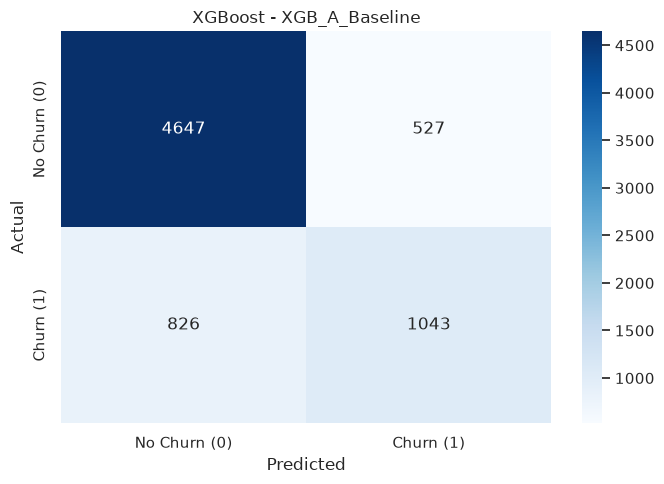

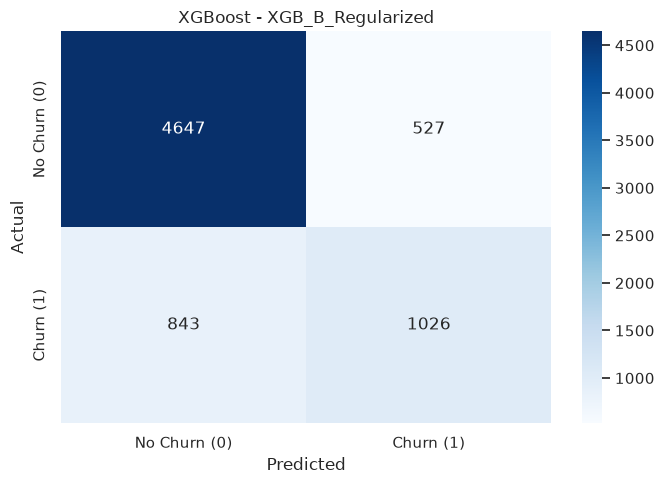

In [19]:
# Matrizes de confusão

for configuration_name, cm in xgb_confusion_matrices.items():

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Churn (0)", "Churn (1)"],
        yticklabels=["No Churn (0)", "Churn (1)"]
    )

    plt.title(f"XGBoost - {configuration_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.tight_layout()
    plt.show()


In [20]:
# Salvando os resultado

# Salvando resultado por fold
xgb_results_df.to_csv(
    results_dir / "xgboost_resultados_por_fold.csv",
    index=False
)

# Salvando sumário dos resultados
xgb_summary.to_csv(
    results_dir / "xgboost_resumo.csv"
)

# Salvando resultado de todos fold
xgb_oof_df.to_csv(
    results_dir / "xgboost_resultados_oof.csv"
)

# Salvando matriz de confusão
for configuration_name, cm in xgb_confusion_matrices.items():

    cm_df = pd.DataFrame(
        cm,
        index=["Actual No Churn", "Actual Churn"],
        columns=["Predicted No Churn", "Predicted Churn"]
    )

    cm_df.to_csv(
        confusion_dir / f"{configuration_name}.csv"
    )


print("Resultados de XGBoost salvos")


Resultados de XGBoost salvos



# 3. K-Nearest Neighbors (KNN)

## 3.1 Objetivo

Implementar e avaliar o algoritmo K-Nearest Neighbors (KNN) para classificar clientes quanto à ocorrência de cancelamento dos serviços de telecomunicações (Churn).

Serão investigadas duas configurações de hiperparâmetros, utilizando as mesmas cinco partições da validação cruzada estratificada empregadas nos experimentos anteriores.

O desempenho será avaliado por meio das métricas de acurácia, precisão, revocação, F1-score e matriz de confusão.


In [21]:

from sklearn.neighbors import KNeighborsClassifier

# Duas configurações de KNN
knn_configurations = {
    "KNN_A_5_Vizinhos": {
        "n_neighbors": 5,
        "weights": "uniform",
        "metric": "euclidean"
    },

    "KNN_B_11_Vizinhos": {
        "n_neighbors": 11,
        "weights": "uniform",
        "metric": "euclidean"
    }
}

display(pd.DataFrame(knn_configurations).T)


,n_neighbors,weights,metric
KNN_A_5_Vizinhos,5,uniform,euclidean
KNN_B_11_Vizinhos,11,uniform,euclidean


In [22]:

# Listas e dicionários para armazenar resultados
knn_results = []
knn_confusion_matrices = {}
knn_oof_results = {}

knn_metric_columns = [
    "accuracy",
    "precision",
    "recall",
    "f1_score"
]

# Executar as duas configurações
for configuration_name, parameters in knn_configurations.items():

    print("\n" + "=" * 65)
    print(f"EXECUTANDO: {configuration_name}")
    print("=" * 65)

    total_confusion_matrix = np.zeros((2, 2), dtype=int)

    all_y_true = []
    all_y_pred = []

    # Validação cruzada com cinco partições
    for fold_number in range(1, 6):

        fold_path = fold_dir / f"fold_{fold_number}.npz"

        # Carregar dados já pré-processados
        with np.load(fold_path, allow_pickle=False) as fold:
            X_train = fold["X_train"]
            X_valid = fold["X_valid"]
            y_train = fold["y_train"]
            y_valid = fold["y_valid"]

        # Criar o classificador
        model = KNeighborsClassifier(**parameters)

        # Treinar
        model.fit(X_train, y_train)

        # Realizar previsões
        y_pred = model.predict(X_valid)

        # Calcular métricas
        accuracy = accuracy_score(y_valid, y_pred)
        precision = precision_score(
            y_valid, y_pred, pos_label=1, zero_division=0
        )
        recall = recall_score(
            y_valid, y_pred, pos_label=1, zero_division=0
        )
        f1 = f1_score(
            y_valid, y_pred, pos_label=1, zero_division=0
        )

        knn_results.append({
            "configuration": configuration_name,
            "fold": fold_number,
            "accuracy": accuracy,
            "precision": precision,
            "recall": recall,
            "f1_score": f1
        })

        # Matriz de confusão
        cm = confusion_matrix(y_valid, y_pred, labels=[0, 1])
        total_confusion_matrix += cm

        # Armazenar previsões
        all_y_true.extend(y_valid)
        all_y_pred.extend(y_pred)

        print(f"Fold {fold_number} concluído.")

    # Matriz de confusão acumulada
    knn_confusion_matrices[configuration_name] = total_confusion_matrix

    # Métricas consolidadas das previsões de validação
    knn_oof_results[configuration_name] = {
        "accuracy": accuracy_score(all_y_true, all_y_pred),
        "precision": precision_score(
            all_y_true, all_y_pred, zero_division=0
        ),
        "recall": recall_score(
            all_y_true, all_y_pred, zero_division=0
        ),
        "f1_score": f1_score(
            all_y_true, all_y_pred, zero_division=0
        )
    }

print("\nValidação cruzada do KNN concluída!")



EXECUTANDO: KNN_A_5_Vizinhos
Fold 1 concluído.
Fold 2 concluído.
Fold 3 concluído.
Fold 4 concluído.
Fold 5 concluído.

EXECUTANDO: KNN_B_11_Vizinhos
Fold 1 concluído.
Fold 2 concluído.
Fold 3 concluído.
Fold 4 concluído.
Fold 5 concluído.

Validação cruzada do KNN concluída!


In [23]:

# Resultados individuais por fold
knn_results_df = pd.DataFrame(knn_results)

display(knn_results_df.round(4))

# Média e desvio-padrão por configuração
knn_summary = (
    knn_results_df
    .groupby("configuration")[knn_metric_columns]
    .agg(["mean", "std"])
)

knn_summary.columns = [
    f"{metric}_{stat}"
    for metric, stat in knn_summary.columns
]

display(knn_summary.round(4))

# Métricas consolidadas
knn_oof_df = pd.DataFrame(knn_oof_results).T

display(knn_oof_df.round(4))


,configuration,fold,accuracy,precision,recall,f1_score
0,KNN_A_5_Vizinhos,1,0.7786,0.5842,0.5749,0.5795
1,KNN_A_5_Vizinhos,2,0.7757,0.5873,0.5214,0.5524
2,KNN_A_5_Vizinhos,3,0.7942,0.6221,0.5722,0.5961
3,KNN_A_5_Vizinhos,4,0.7628,0.5521,0.5668,0.5594
4,KNN_A_5_Vizinhos,5,0.7834,0.5919,0.5871,0.5895
5,KNN_B_11_Vizinhos,1,0.7921,0.6181,0.5668,0.5914
6,KNN_B_11_Vizinhos,2,0.7828,0.6000,0.5455,0.5714
7,KNN_B_11_Vizinhos,3,0.8062,0.6431,0.6070,0.6245
8,KNN_B_11_Vizinhos,4,0.7727,0.5746,0.5561,0.5652
9,KNN_B_11_Vizinhos,5,0.7997,0.6233,0.6166,0.6199


,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_score_mean,f1_score_std
configuration,,,,,,,,
KNN_A_5_Vizinhos,0.7789,0.0114,0.5875,0.0249,0.5645,0.0252,0.5754,0.0189
KNN_B_11_Vizinhos,0.7907,0.0133,0.6118,0.0259,0.5784,0.0316,0.5945,0.0271


,accuracy,precision,recall,f1_score
KNN_A_5_Vizinhos,0.7789,0.5868,0.5645,0.5754
KNN_B_11_Vizinhos,0.7907,0.6118,0.5784,0.5946


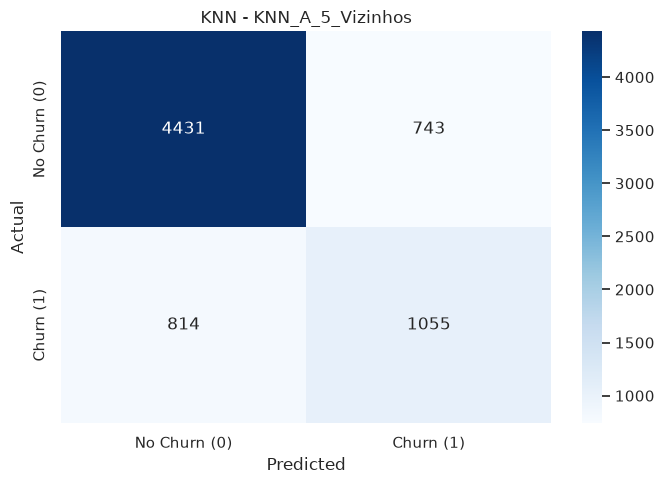

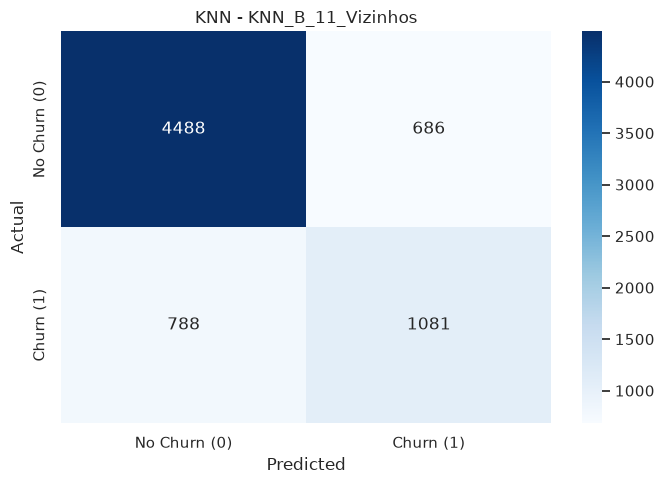

In [24]:

for configuration_name, cm in knn_confusion_matrices.items():

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Churn (0)", "Churn (1)"],
        yticklabels=["No Churn (0)", "Churn (1)"]
    )

    plt.title(f"KNN - {configuration_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.tight_layout()
    plt.show()


In [25]:

# Salvar resultados por fold
knn_results_df.to_csv(
    results_dir / "knn_resultados_por_fold.csv",
    index=False
)

# Salvar resumo
knn_summary.to_csv(
    results_dir / "knn_resumo.csv"
)

# Salvar métricas consolidadas
knn_oof_df.to_csv(
    results_dir / "knn_resultados_oof.csv"
)

# Salvar matrizes de confusão
confusion_dir = results_dir / "matrizes_confusao"
confusion_dir.mkdir(parents=True, exist_ok=True)

for configuration_name, cm in knn_confusion_matrices.items():

    cm_df = pd.DataFrame(
        cm,
        index=["Actual No Churn", "Actual Churn"],
        columns=["Predicted No Churn", "Predicted Churn"]
    )

    cm_df.to_csv(
        confusion_dir / f"{configuration_name}.csv"
    )

print("Resultados do KNN salvos com sucesso!")


Resultados do KNN salvos com sucesso!



# 4. Support Vector Machine (SVM)

## 4.1 Objetivo

Implementar e avaliar o algoritmo Support Vector Machine (SVM) para classificar clientes quanto à ocorrência de cancelamento dos serviços de telecomunicações (Churn).

Serão comparadas duas configurações de hiperparâmetros, utilizando as mesmas cinco partições da validação cruzada estratificada empregadas nos demais classificadores.

A comparação considera um kernel linear e um kernel RBF (Radial Basis Function), permitindo avaliar o comportamento do SVM com diferentes fronteiras de decisão.

O desempenho será avaliado por meio das métricas de acurácia, precisão, revocação, F1-score e matriz de confusão.


In [26]:

from sklearn.svm import SVC

# Duas configurações do SVM
svm_configurations = {
    "SVM_A_Linear": {
        "kernel": "linear",
        "C": 1.0
    },

    "SVM_B_RBF": {
        "kernel": "rbf",
        "C": 1.0,
        "gamma": "scale"
    }
}

display(pd.DataFrame(svm_configurations).T)


,kernel,C,gamma
SVM_A_Linear,linear,1.0,NaN
SVM_B_RBF,rbf,1.0,scale


In [27]:

# Listas e dicionários para armazenar os resultados
svm_results = []
svm_confusion_matrices = {}
svm_oof_results = {}

svm_metric_columns = [
    "accuracy",
    "precision",
    "recall",
    "f1_score"
]

# Executar as duas configurações
for configuration_name, parameters in svm_configurations.items():

    print("\n" + "=" * 65)
    print(f"EXECUTANDO: {configuration_name}")
    print("=" * 65)

    total_confusion_matrix = np.zeros((2, 2), dtype=int)

    all_y_true = []
    all_y_pred = []

    # Validação cruzada com cinco partições
    for fold_number in range(1, 6):

        fold_path = fold_dir / f"fold_{fold_number}.npz"

        # Carregar os dados já pré-processados
        with np.load(fold_path, allow_pickle=False) as fold:
            X_train = fold["X_train"]
            X_valid = fold["X_valid"]
            y_train = fold["y_train"]
            y_valid = fold["y_valid"]

        # Criar o classificador
        model = SVC(**parameters)

        # Treinar o modelo
        model.fit(X_train, y_train)

        # Realizar as previsões
        y_pred = model.predict(X_valid)

        # Calcular as métricas
        accuracy = accuracy_score(y_valid, y_pred)

        precision = precision_score(
            y_valid, y_pred,
            pos_label=1,
            zero_division=0
        )

        recall = recall_score(
            y_valid, y_pred,
            pos_label=1,
            zero_division=0
        )

        f1 = f1_score(
            y_valid, y_pred,
            pos_label=1,
            zero_division=0
        )

        # Armazenar os resultados do fold
        svm_results.append({
            "configuration": configuration_name,
            "fold": fold_number,
            "accuracy": accuracy,
            "precision": precision,
            "recall": recall,
            "f1_score": f1
        })

        # Matriz de confusão
        cm = confusion_matrix(
            y_valid, y_pred, labels=[0, 1]
        )

        total_confusion_matrix += cm

        # Armazenar as previsões de validação
        all_y_true.extend(y_valid)
        all_y_pred.extend(y_pred)

        print(f"Fold {fold_number} concluído.")

    # Matriz de confusão acumulada
    svm_confusion_matrices[configuration_name] = total_confusion_matrix

    # Métricas consolidadas das previsões de validação
    svm_oof_results[configuration_name] = {
        "accuracy": accuracy_score(all_y_true, all_y_pred),
        "precision": precision_score(
            all_y_true, all_y_pred, zero_division=0
        ),
        "recall": recall_score(
            all_y_true, all_y_pred, zero_division=0
        ),
        "f1_score": f1_score(
            all_y_true, all_y_pred, zero_division=0
        )
    }

print("\nValidação cruzada do SVM concluída!")



EXECUTANDO: SVM_A_Linear
Fold 1 concluído.
Fold 2 concluído.
Fold 3 concluído.
Fold 4 concluído.
Fold 5 concluído.

EXECUTANDO: SVM_B_RBF
Fold 1 concluído.
Fold 2 concluído.
Fold 3 concluído.
Fold 4 concluído.
Fold 5 concluído.

Validação cruzada do SVM concluída!


In [28]:

# Resultados individuais por fold
svm_results_df = pd.DataFrame(svm_results)

display(svm_results_df.round(4))

# Média e desvio-padrão por configuração
svm_summary = (
    svm_results_df
    .groupby("configuration")[svm_metric_columns]
    .agg(["mean", "std"])
)

svm_summary.columns = [
    f"{metric}_{stat}"
    for metric, stat in svm_summary.columns
]

display(svm_summary.round(4))

# Métricas consolidadas
svm_oof_df = pd.DataFrame(svm_oof_results).T

display(svm_oof_df.round(4))


,configuration,fold,accuracy,precision,recall,f1_score
0,SVM_A_Linear,1,0.8126,0.6687,0.5829,0.6229
1,SVM_A_Linear,2,0.7977,0.6413,0.5401,0.5864
2,SVM_A_Linear,3,0.8077,0.6722,0.5374,0.5973
3,SVM_A_Linear,4,0.7955,0.6327,0.5481,0.5874
4,SVM_A_Linear,5,0.8182,0.6811,0.5898,0.6322
5,SVM_B_RBF,1,0.8070,0.6735,0.5294,0.5928
6,SVM_B_RBF,2,0.8020,0.6715,0.4973,0.5714
7,SVM_B_RBF,3,0.8190,0.7148,0.5294,0.6083
8,SVM_B_RBF,4,0.8004,0.6545,0.5267,0.5837
9,SVM_B_RBF,5,0.8168,0.6976,0.5442,0.6114


,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_score_mean,f1_score_std
configuration,,,,,,,,
SVM_A_Linear,0.8063,0.0097,0.6592,0.0210,0.5597,0.0248,0.6052,0.0211
SVM_B_RBF,0.8090,0.0085,0.6824,0.0238,0.5254,0.0172,0.5935,0.0168


,accuracy,precision,recall,f1_score
SVM_A_Linear,0.8063,0.6591,0.5597,0.6053
SVM_B_RBF,0.8090,0.6819,0.5254,0.5935


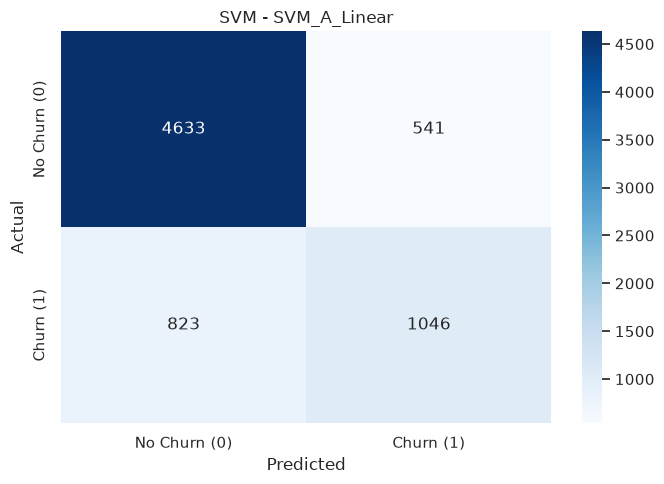

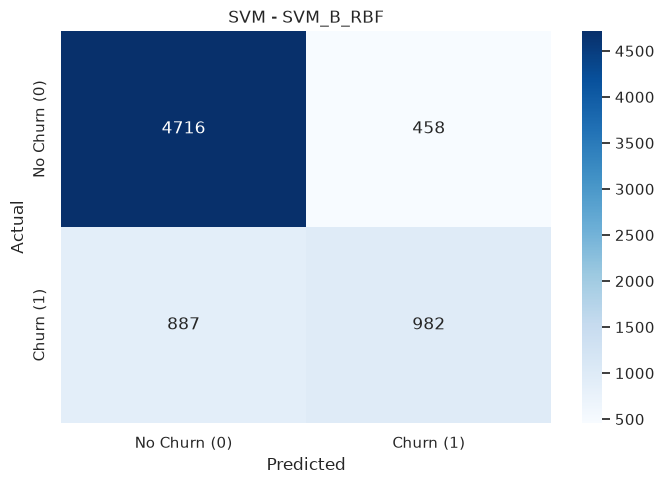

In [29]:

for configuration_name, cm in svm_confusion_matrices.items():

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Churn (0)", "Churn (1)"],
        yticklabels=["No Churn (0)", "Churn (1)"]
    )

    plt.title(f"SVM - {configuration_name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")

    plt.tight_layout()
    plt.show()


In [30]:

# Salvar resultados por fold
svm_results_df.to_csv(
    results_dir / "svm_resultados_por_fold.csv",
    index=False
)

# Salvar resumo das métricas
svm_summary.to_csv(
    results_dir / "svm_resumo.csv"
)

# Salvar métricas consolidadas
svm_oof_df.to_csv(
    results_dir / "svm_resultados_oof.csv"
)

# Criar pasta das matrizes de confusão
confusion_dir = results_dir / "matrizes_confusao"
confusion_dir.mkdir(parents=True, exist_ok=True)

# Salvar matrizes de confusão
for configuration_name, cm in svm_confusion_matrices.items():

    cm_df = pd.DataFrame(
        cm,
        index=["Actual No Churn", "Actual Churn"],
        columns=["Predicted No Churn", "Predicted Churn"]
    )

    cm_df.to_csv(
        confusion_dir / f"{configuration_name}.csv"
    )

print("Resultados do SVM salvos com sucesso!")


Resultados do SVM salvos com sucesso!
